In [1]:
import pandas as pd

# Specify the path to your Excel file
excel_file_path = 'GBM_Bibliography_Abstracts.xlsx'

# Specify the sheet name
sheet_name = 'Bibliography'

# Read a specific sheet into a DataFrame
df = pd.read_excel(excel_file_path, sheet_name=sheet_name)

# # Create a sample DataFrame
# data = {'Name': ['Alice', 'Bob', 'Charlie'],
#         'Age': [25, 30, 35],
#         'City': ['New York', 'San Francisco', 'Los Angeles']}

# Display the DataFrame
# print(df)

In [2]:
import numpy as np
import torch
# from os import listdir, makedirs
# from os.path import isfile, join, splitext, exists

from transformers import BertModel, BertTokenizer
model = BertModel.from_pretrained('bert-base-uncased',
           output_hidden_states = True,)
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertModel: ['cls.predictions.transform.LayerNorm.weight', 'cls.seq_relationship.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.seq_relationship.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.predictions.bias']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


In [10]:
# Extract features
def extract_features(data_frame):
    
    feature_vectors = []
    IDs = []
    
    # Iterate through rows using iterrows()
    for index, row in data_frame.iterrows():
        ID = row['ID']
        text = row['Title'] + ' ' + row['Abstract']
        
        # print(f"Index: {index}, ID: {ID}, Text: {text}")
        
        
        if index % 10 == 0:
            print("Processing sample %d..." % (index))
            
        tokens = tokenizer(text, truncation=False, return_tensors='pt')        
        if tokens.input_ids.shape[1] > 512:
            print("Too many tokens for %s: %d" % (ID, tokens.input_ids.shape[1]))
        
        tokens = tokenizer(text, truncation=True, max_length=512, return_tensors='pt')
        outputs = model(**tokens, output_hidden_states=True)
        
        last_hidden_states = outputs.hidden_states[-1] # last layer hidden states
        
        cls_token = torch.mean(last_hidden_states[0], dim=0)#last_hidden_states[0,0,:]
        
        feature_vector = np.squeeze(cls_token.detach().numpy())
        feature_vectors += [feature_vector]
        IDs += [ID]
        
    return feature_vectors, IDs
        
feature_vectors, IDs = extract_features(df)

Processing sample 0...
Too many tokens for Aaronson et al.: 543
Too many tokens for Bota et al.: 542
Processing sample 10...
Too many tokens for Cabezas-Camarero et al.: 627
Processing sample 20...
Too many tokens for Chang et al.: 708
Processing sample 30...
Too many tokens for Gibson et al.: 557
Processing sample 40...
Too many tokens for Herrlinger et al.: 802
Too many tokens for Holst et al. (b): 558
Processing sample 50...
Too many tokens for Juratli et al.: 637
Processing sample 60...
Too many tokens for Lassman et al.: 580
Too many tokens for Lombardi et al.: 749
Processing sample 70...
Too many tokens for Ma et al. (b): 531
Processing sample 80...
Too many tokens for Norden et al.: 940
Processing sample 90...
Too many tokens for Ostrom et al.: 539
Too many tokens for Price et al.: 597
Too many tokens for Reardon et al.: 709
Processing sample 100...
Too many tokens for Schlehofer et al.: 685
Too many tokens for Schwartzbaum et al. (a): 516
Too many tokens for Seyhan: 572
Process

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
def extract_tfidf(df):
    df['text'] = df['Title'] + ' ' + df['Abstract']
    tfidf_vectorizer = TfidfVectorizer(stop_words='english')
    tfidf = tfidf_vectorizer.fit_transform(df['text'])
    return tfidf.toarray(), list(df['ID'])
# feature_vectors, IDs = extract_tfidf(df)

/Users/raduionescu/opt/anaconda3/envs/ml/lib/python3.7/site-packages/sklearn/feature_extraction/image.py:167: DeprecationWarning: `np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  dtype=np.int):


149
Max inco: 0.604359


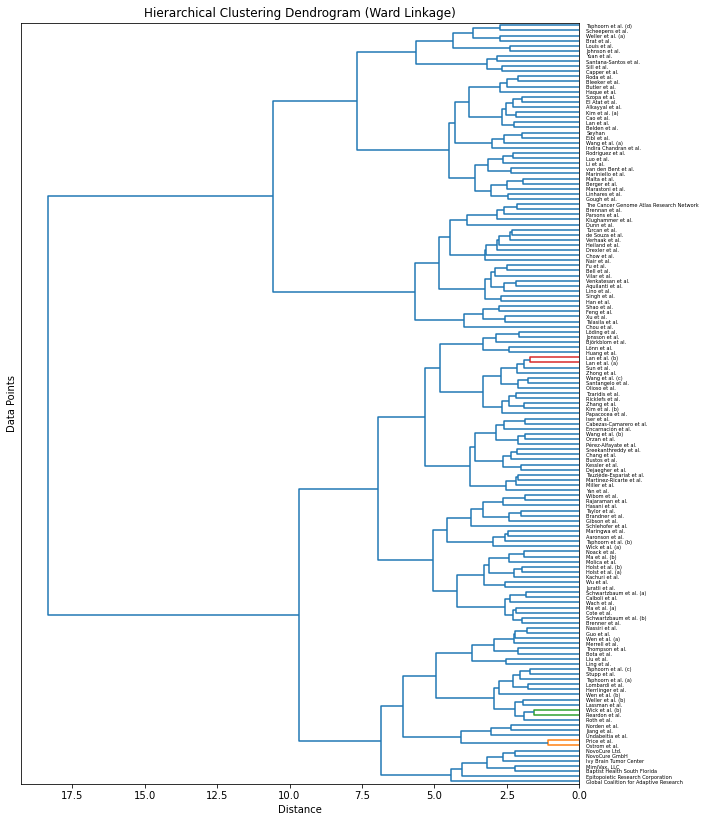

In [18]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, median, inconsistent, maxinconsts
from scipy.spatial.distance import pdist
import numpy as np
print(len(IDs))
# Generate some random data for demonstration
np.random.seed(837)

D = pdist(feature_vectors, 'euclidean')

# Perform hierarchical clustering using Ward linkage
linkage_matrix = linkage(feature_vectors, method='ward')
R = inconsistent(linkage_matrix)

max_inco = maxinconsts(linkage_matrix, R)
# print(max_inco)
print("Max inco: %f" % (np.mean(max_inco)))

# Display the dendrogram
plt.figure(figsize=(10, 14))
dendrogram(linkage_matrix, labels=IDs, color_threshold=1.7, orientation = 'left')
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)')
plt.ylabel('Data Points')
# plt.xlim(1.4, 0.8)
plt.xlabel('Distance')
plt.savefig('GBM_dendrogram_BERT_1.7.pdf', bbox_inches='tight', pad_inches=0.2)
plt.show()